# ResNeXt — Aggregated Residual Transformations for Deep Neural Networks

**Citation:** Xie, S., Girshick, R., Dollár, P., Tu, Z., & He, K. (2017). Aggregated residual transformations for deep neural networks. *CVPR 2017*. arXiv:1611.05431.

**Registered names:** `resnext50_32x4d`, `resnext101_32x4d`, `resnext101_32x8d`

**Summary:** ResNeXt introduces *cardinality* — the number of parallel transformation groups — as a new dimension of scaling beyond depth and width. A 32×4d ResNeXt-50 matches ResNet-50 accuracy at fewer FLOPs, and matches ResNet-101 at ResNet-50's complexity.

---

| Model | Layers | C × D | Params | Top-1 |
|-------|--------|-------|--------|-------|
| ResNeXt-50 (32×4d) | 50 | 32 × 4 | 25.0M | 77.6% |
| ResNeXt-101 (32×4d) | 101 | 32 × 4 | 44.2M | 78.8% |
| ResNeXt-101 (32×8d) | 101 | 32 × 8 | 88.8M | 79.3% |

> 📄 **Paper:** Xie, Girshick, Dollár, Tu & He (2017). Aggregated Residual Transformations for Deep Neural Networks. CVPR 2017.
> 🔗 **Link:** <https://arxiv.org/abs/1611.05431>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/resnext.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["stem /4"]:::stage --> S["4 stages ×[3,4,6,3], /4 /8 /16 /32"]:::stage --> GAP["avg pool"]:::block --> OUT
  subgraph BLK["ResNeXt block (cardinality 32, width 4d)"]
    direction LR
    X["x (256)"] --> A["1×1 → 128"]:::block --> G["grouped 3×3, groups = 32<br/>(32 paths × 4 ch)"]:::block --> C["1×1 → 256"]:::block --> ADD(("+"))
    X --> ADD
  end
  S -.-> BLK
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Diagram

```
ResNet Bottleneck vs ResNeXt Bottleneck (32×4d)

ResNet:                    ResNeXt (32×4d):
─────────────────          ──────────────────────────
in [B, C_in, H, W]         in [B, C_in, H, W]
      │                          │
 Conv 1×1 (→planes)         Conv 1×1 (→128)      ← width = C*D = 32*4 = 128
      │                          │
 Conv 3×3 (→planes)         GroupConv 3×3        ← groups=32 (cardinality)
      │                     (128→128, g=32)
 Conv 1×1 (→planes*4)            │
      │                     Conv 1×1 (→planes*4)
 + residual                      │
      │                    + residual
 ReLU                       ReLU

Insight: 32 groups of width-4 convolutions = 1 grouped conv.
Same FLOPs as ResNet but captures 32 independent transformation paths.

Full network (same as ResNet):
  Stem → Stage0(256ch) → Stage1(512ch) → Stage2(1024ch) → Stage3(2048ch)
  → GlobalAvgPool → pooled [B, 2048]
```

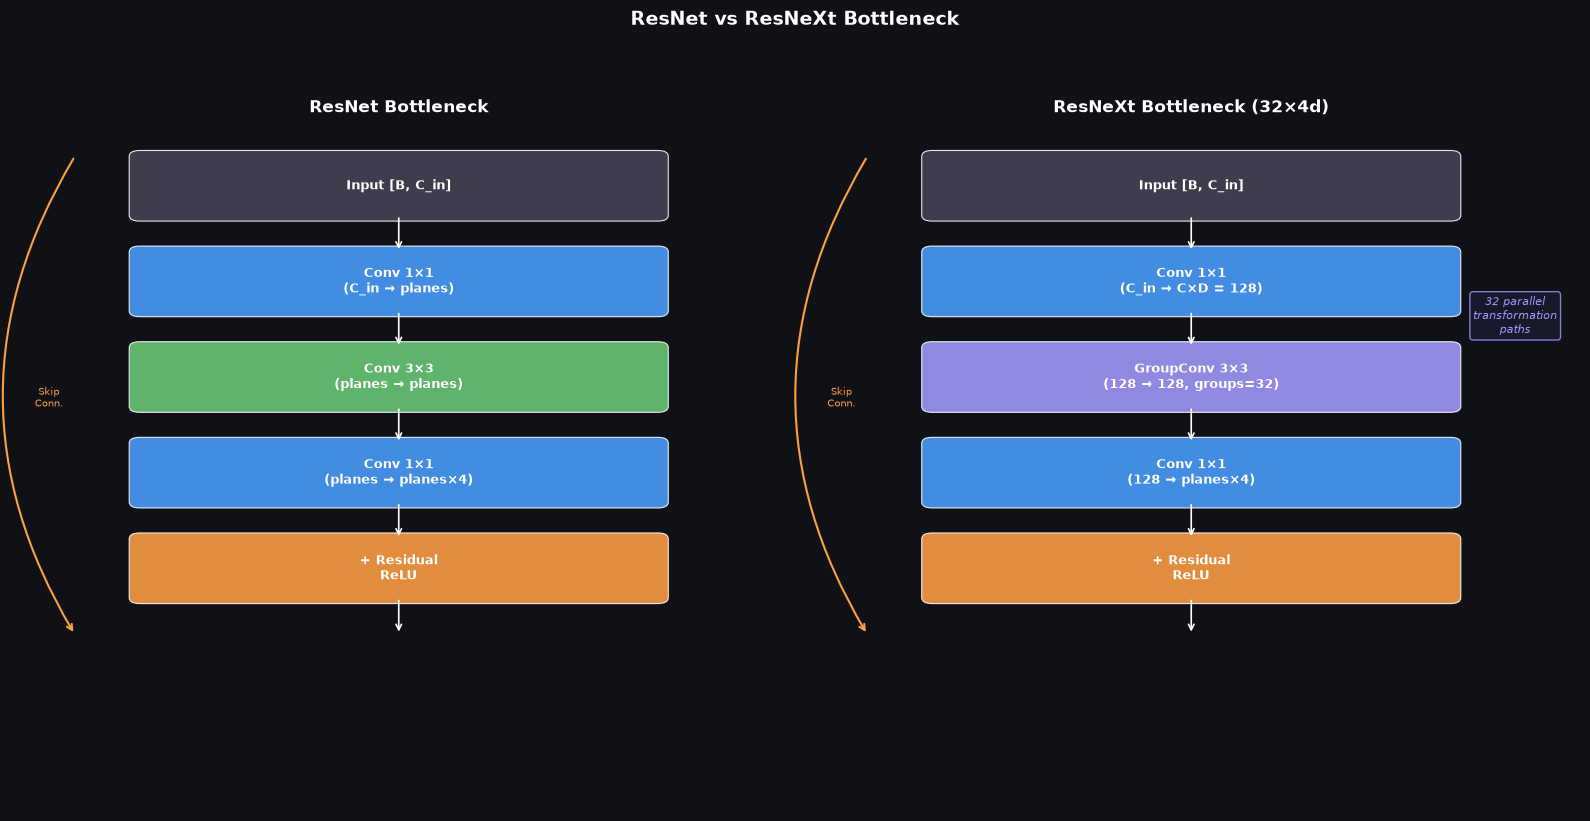

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
fig.patch.set_facecolor('#0f1117')

def draw_bottleneck(ax, title, layers, colors, x_start=1.5):
    ax.set_facecolor('#0f1117')
    ax.set_xlim(0, 6); ax.set_ylim(0, 10); ax.axis('off')
    ax.text(3, 9.5, title, ha='center', color='white', fontsize=12, fontweight='bold')

    y = 8.5
    for label, color in zip(layers, colors):
        ax.add_patch(FancyBboxPatch((1.0, y - 0.4), 4.0, 0.8,
                                     boxstyle='round,pad=0.08', facecolor=color,
                                     edgecolor='white', linewidth=0.8, alpha=0.88))
        ax.text(3.0, y, label, ha='center', va='center', color='white', fontsize=9, fontweight='bold')
        if y > 2.5:
            ax.annotate('', xy=(3.0, y - 0.9), xytext=(3.0, y - 0.4),
                        arrowprops=dict(arrowstyle='->', color='white', lw=1.2))
        y -= 1.3

    # Residual connection
    ax.annotate('', xy=(0.5, y + 0.4), xytext=(0.5, 8.9),
                arrowprops=dict(arrowstyle='->', color='#ff9f43', lw=1.5,
                                connectionstyle='arc3,rad=0.3'))
    ax.text(0.3, 5.5, 'Skip\nConn.', ha='center', color='#ff9f43', fontsize=7)

resnet_layers = [
    'Input [B, C_in]',
    'Conv 1×1\n(C_in → planes)',
    'Conv 3×3\n(planes → planes)',
    'Conv 1×1\n(planes → planes×4)',
    '+ Residual\nReLU',
]
resnet_colors = ['#444455', '#4a9eff', '#6bcb77', '#4a9eff', '#ff9f43']
draw_bottleneck(axes[0], 'ResNet Bottleneck', resnet_layers, resnet_colors)

resnext_layers = [
    'Input [B, C_in]',
    'Conv 1×1\n(C_in → C×D = 128)',
    'GroupConv 3×3\n(128 → 128, groups=32)',
    'Conv 1×1\n(128 → planes×4)',
    '+ Residual\nReLU',
]
resnext_colors = ['#444455', '#4a9eff', '#a29bfe', '#4a9eff', '#ff9f43']
draw_bottleneck(axes[1], 'ResNeXt Bottleneck (32×4d)', resnext_layers, resnext_colors)

# GroupConv annotation
axes[1].text(5.5, 6.5, '32 parallel\ntransformation\npaths', ha='center',
             color='#a29bfe', fontsize=8, style='italic',
             bbox=dict(boxstyle='round', facecolor='#1a1a2e', edgecolor='#a29bfe', alpha=0.8))

plt.suptitle('ResNet vs ResNeXt Bottleneck', color='white', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 3. Key ideas

## Key Innovations

### 1. Cardinality — A New Dimension of Scaling
ResNeXt proposes cardinality $C$ (number of transformation groups) as the third axis of scaling:
- **Depth** (ResNet: more layers)
- **Width** (WideResNet: wider channels)
- **Cardinality** (ResNeXt: more transformation groups)

The bottleneck width $D$ is chosen so total FLOPs ≈ ResNet:
$$\text{mid\_ch} = \left\lfloor \frac{\text{planes}}{64} \cdot D \right\rfloor \times C$$

### 2. Three Equivalent Formulations
The paper shows three mathematically equivalent implementations:
1. **Aggregated transformation**: $C$ independent branches summed before projection
2. **Grouped convolution**: Single `Conv(groups=C)` call (most efficient)
3. **Concatenation shortcut**: Input split into $C$ groups, processed independently, concatenated

We use formulation 2 (grouped convolution) for efficiency:
```python
self.conv2 = nn.Conv2d(mid_ch, mid_ch, kernel_size=3, stride=stride,
                       padding=1, groups=cardinality, bias=False)
```

### 3. Scaling Law
Experimental finding: increasing cardinality is more effective than increasing width at the same model complexity. A 32×4d ResNeXt-101 outperforms a 1×64d (standard ResNet-101) with similar parameters.

## Code Walkthrough

Implemented in `hale_core/nn/vision/cnn/resnext.py`.

**ResNeXtBottleneck — grouped conv as aggregated transformation:**
```python
class ResNeXtBottleneck(nn.Module):
    expansion = 4

    def __init__(self, in_planes, planes, stride=1,
                 cardinality=32, base_width=4, downsample=None):
        # mid_ch = C * D; at ResNet's 'planes=64', C=32, D=4 → mid_ch=128
        mid_ch = int(planes * (base_width / 64.0)) * cardinality
        self.conv1 = nn.Conv2d(in_planes, mid_ch, kernel_size=1, bias=False)
        self.conv2 = nn.Conv2d(mid_ch, mid_ch, kernel_size=3, stride=stride,
                               padding=1, groups=cardinality, bias=False)  # KEY
        self.conv3 = nn.Conv2d(mid_ch, planes * 4, kernel_size=1, bias=False)
```

The only change vs ResNet's Bottleneck is `groups=cardinality` in `conv2`. Everything else (stage structure, shortcut projection, weight init) is identical.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/resnext.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/resnext.py</code></summary>

```text
ResNeXt Vision Backbones
========================

Implements the ResNeXt family (Xie et al. CVPR 2017, "Aggregated Residual
Transformations for Deep Neural Networks").

The key insight: instead of a single "wider" convolution, use a group of
"narrower" convolutions (cardinality C) — aggregated transformations that
are computationally equivalent to a grouped convolution.  This improves
accuracy without increasing FLOPs, adding a new dimension to scaling beyond
depth and width.

Architecture
------------
ResNeXt uses the same 4-stage hierarchy as ResNet but replaces the 3×3 conv
in each Bottleneck with a grouped convolution:

  ResNeXtBottleneck (32×4d, i.e. 32 groups × 4 width):
    1×1 Conv(in → C*D)          — reduce to grouped width
    3×3 GroupConv(C*D → C*D, groups=C) — aggregated transformations
    1×1 Conv(C*D → planes×4)   — expand to output channels
    + residual shortcut

  where C = cardinality (groups), D = base_width per group
  For 32×4d: C=32, D=4, so mid_ch = C*D = 128
  For 32×8d: C=32, D=8, so mid_ch = C*D = 256

Stage structure identical to ResNet:
  Stem → Stage 0 (64→256) → Stage 1 (128→512) → Stage 2 (256→1024) → Stage 3 (512→2048)
  embed_dim = 2048 for all variants (same as ResNet50/101).

Registered names
----------------
  resnext50_32x4d   — [3, 4, 6, 3]  × ResNeXtBottleneck(C=32, D=4)
  resnext101_32x4d  — [3, 4, 23, 3] × ResNeXtBottleneck(C=32, D=4)
  resnext101_32x8d  — [3, 4, 23, 3] × ResNeXtBottleneck(C=32, D=8)

Citation
--------
  Xie, S., Girshick, R., Dollár, P., Tu, Z., & He, K. (2017). Aggregated
  Residual Transformations for Deep Neural Networks. CVPR 2017. arXiv:1611.05431.
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### 4.2 `cnn/resnext.py`, definition by definition

**`ResNeXtBottleneck`** - ResNeXt Bottleneck with grouped (cardinality) convolution.

In [5]:
class ResNeXtBottleneck(nn.Module):
    """ResNeXt Bottleneck with grouped (cardinality) convolution.

    The key difference from standard Bottleneck: the 3×3 conv uses groups=C
    (cardinality), which implements C parallel transformations of equal width.
    Mathematically equivalent to a width-C grouped conv but much more expressive
    than a single wider conv at the same parameter budget.

    Args:
        in_planes:   Input channels.
        planes:      Stage "planes" (output = planes * expansion = planes * 4).
        stride:      Stride for the 3×3 grouped conv.
        cardinality: Number of transformation groups (default 32).
        base_width:  Width per group in the bottleneck (default 4).
        downsample:  Optional projection shortcut.
    """
    expansion: int = 4

    def __init__(
        self,
        in_planes:   int,
        planes:      int,
        stride:      int = 1,
        cardinality: int = 32,
        base_width:  int = 4,
        downsample: Optional[nn.Module] = None,
    ) -> None:
        super().__init__()
        # Bottleneck width = C * D; at the standard stage channel counts this
        # gives much wider intermediate features than ResNet bottleneck at similar cost
        mid_ch = int(planes * (base_width / 64.0)) * cardinality

        self.conv1 = nn.Conv2d(in_planes, mid_ch, kernel_size=1, bias=False)
        self.bn1   = nn.BatchNorm2d(mid_ch)

        # Grouped conv: groups=cardinality implements the aggregated transformation
        self.conv2 = nn.Conv2d(mid_ch, mid_ch, kernel_size=3, stride=stride,
                               padding=1, groups=cardinality, bias=False)
        self.bn2   = nn.BatchNorm2d(mid_ch)

        out_ch = planes * self.expansion
        self.conv3 = nn.Conv2d(mid_ch, out_ch, kernel_size=1, bias=False)
        self.bn3   = nn.BatchNorm2d(out_ch)

        self.downsample = downsample

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = x
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = F.relu(self.bn2(self.conv2(out)), inplace=True)
        out = self.bn3(self.conv3(out))
        if self.downsample is not None:
            identity = self.downsample(x)
        return F.relu(out + identity, inplace=True)

**`ResNeXt`** - Generic ResNeXt backbone.

In [6]:
class ResNeXt(BaseVisionBackbone):
    """Generic ResNeXt backbone.

    Same 4-stage structure as ResNet but using grouped bottleneck blocks.

    Args:
        layers:      Number of blocks per stage [s0, s1, s2, s3].
        cardinality: Transformation groups (C in the paper).
        base_width:  Width per group at stage channels (D in the paper).
        img_size:    Input resolution.
        in_chans:    Input channels.
        drop_rate:   Dropout after global pooling.
    """

    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(
        self,
        layers:      list[int],
        cardinality: int   = 32,
        base_width:  int   = 4,
        img_size:    int   = 224,
        in_chans:    int   = 3,
        drop_rate:   float = 0.0,
        **kwargs,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate)

        self._cardinality = cardinality
        self._base_width  = base_width
        self._in_planes   = 64

        # Stem: same as ResNet — 7×7 conv → BN → ReLU → MaxPool
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, 64, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        self.stage0 = self._make_stage( 64, layers[0], stride=1)
        self.stage1 = self._make_stage(128, layers[1], stride=2)
        self.stage2 = self._make_stage(256, layers[2], stride=2)
        self.stage3 = self._make_stage(512, layers[3], stride=2)

        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._stages = [self.stage0, self.stage1, self.stage2, self.stage3]
        self._init_weights()

    def _make_stage(self, planes: int, n_blocks: int, stride: int) -> nn.Sequential:
        out_ch = planes * ResNeXtBottleneck.expansion
        downsample = None
        if stride != 1 or self._in_planes != out_ch:
            downsample = nn.Sequential(
                nn.Conv2d(self._in_planes, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )

        blocks = [ResNeXtBottleneck(
            self._in_planes, planes, stride,
            cardinality=self._cardinality,
            base_width=self._base_width,
            downsample=downsample,
        )]
        self._in_planes = out_ch

        for _ in range(1, n_blocks):
            blocks.append(ResNeXtBottleneck(
                self._in_planes, planes,
                cardinality=self._cardinality,
                base_width=self._base_width,
            ))
        return nn.Sequential(*blocks)

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
        # Zero-init last BN in each bottleneck for training stability
        for m in self.modules():
            if isinstance(m, ResNeXtBottleneck):
                nn.init.zeros_(m.bn3.weight)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        x  = self.stem(x)

        s0 = self.stage0(x)   # [B, 256,  H/4,  W/4]
        s1 = self.stage1(s0)  # [B, 512,  H/8,  W/8]
        s2 = self.stage2(s1)  # [B, 1024, H/16, W/16]
        s3 = self.stage3(s2)  # [B, 2048, H/32, W/32]

        pooled = self.dropout(self.pool(s3).flatten(1))  # [B, 2048]

        all_maps = [s0, s1, s2, s3]
        if self.out_indices is not None:
            all_maps = [all_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self._stages[i].parameters():
                p.requires_grad_(False)

**`ResNeXt50_32x4d`** - ResNeXt-50 (32×4d): Bottleneck×[3,4,6,3], C=32, D=4, embed_dim=2048.

In [7]:
@register_vision_backbone("resnext50_32x4d")
class ResNeXt50_32x4d(ResNeXt):
    """ResNeXt-50 (32×4d): Bottleneck×[3,4,6,3], C=32, D=4, embed_dim=2048."""
    arch_name    = "resnext50_32x4d"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs):
        super().__init__([3, 4, 6, 3], cardinality=32, base_width=4, **kwargs)

**`ResNeXt101_32x4d`** - ResNeXt-101 (32×4d): Bottleneck×[3,4,23,3], C=32, D=4, embed_dim=2048.

In [8]:
@register_vision_backbone("resnext101_32x4d")
class ResNeXt101_32x4d(ResNeXt):
    """ResNeXt-101 (32×4d): Bottleneck×[3,4,23,3], C=32, D=4, embed_dim=2048."""
    arch_name    = "resnext101_32x4d"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs):
        super().__init__([3, 4, 23, 3], cardinality=32, base_width=4, **kwargs)

**`ResNeXt101_32x8d`** - ResNeXt-101 (32×8d): Bottleneck×[3,4,23,3], C=32, D=8, embed_dim=2048.

In [9]:
@register_vision_backbone("resnext101_32x8d")
class ResNeXt101_32x8d(ResNeXt):
    """ResNeXt-101 (32×8d): Bottleneck×[3,4,23,3], C=32, D=8, embed_dim=2048."""
    arch_name    = "resnext101_32x8d"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs):
        super().__init__([3, 4, 23, 3], cardinality=32, base_width=8, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [10]:
DEMOS = {"resnext50_32x4d": 25.0}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['resnext101_32x4d', 'resnext101_32x8d', 'resnext50_32x4d']



resnext50_32x4d  (ResNeXt50_32x4d)
  pooled_output : (2, 2048)   embed_dim = 2048
  feature_map 0: (2, 256, 56, 56)   stride 4
  feature_map 1: (2, 512, 28, 28)   stride 8
  feature_map 2: (2, 1024, 14, 14)   stride 16
  feature_map 3: (2, 2048, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [11]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
resnext50_32x4d          22.98M     25.03M    25.0M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [12]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

resnext50_32x4d: loss 2.1597 | 159/159 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [13]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

resnext50_32x4d: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

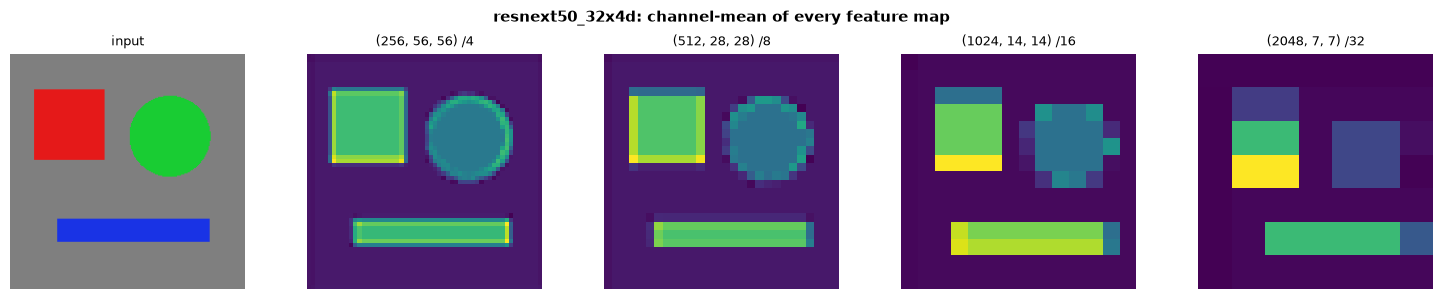

In [14]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [15]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [16]:
import torch
import sys


for name in ['resnext50_32x4d', 'resnext101_32x4d', 'resnext101_32x8d']:
    bb = build_vision_backbone(name, img_size=224)
    bb.eval()
    x = torch.randn(1, 3, 224, 224)
    with torch.no_grad():
        out = bb(x)
    print(f'{name}:')
    print(f'  pooled:       {tuple(out.pooled_output.shape)}')
    print(f'  feature_maps: {[tuple(f.shape) for f in out.feature_maps]}')
    print(f'  params:       {bb.num_parameters()/1e6:.1f}M')

resnext50_32x4d:
  pooled:       (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params:       23.0M


resnext101_32x4d:
  pooled:       (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params:       42.1M


resnext101_32x8d:
  pooled:       (1, 2048)
  feature_maps: [(1, 256, 56, 56), (1, 512, 28, 28), (1, 1024, 14, 14), (1, 2048, 7, 7)]
  params:       86.7M


## References

| Paper | Venue | Key Contribution |
|-------|-------|------------------|
| Xie et al. (2017). Aggregated Residual Transformations. | CVPR 2017 | ResNeXt — cardinality as scaling dimension |
| He et al. (2016). Deep Residual Learning. | CVPR 2016 | ResNet — skip connections |
| Zagoruyko & Komodakis (2016). Wide Residual Networks. | BMVC 2016 | WideResNet — width scaling |
| Howard et al. (2017). MobileNets. | arXiv 2017 | Depthwise separable = extreme cardinality case |
| Krizhevsky et al. (2012). ImageNet Classification. | NeurIPS 2012 | AlexNet — grouped conv in original paper |

**Full Citation:**
> Xie, S., Girshick, R., Dollár, P., Tu, Z., & He, K. (2017). Aggregated residual transformations for deep neural networks. In *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 1492–1500). arXiv:1611.05431.